In [1]:
import boto3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

BUCKET = "dsan6000-my677"
PREFIX = "wikipedia-hourly/"

s3 = boto3.client("s3")
paginator = s3.get_paginator("list_objects_v2")
keys = sorted(
    obj["Key"]
    for page in paginator.paginate(Bucket=BUCKET, Prefix=PREFIX)
    for obj in page.get("Contents", [])
    if obj["Key"].endswith(".parquet")
)

dfs = []
for key in keys:
    hour_df = pd.read_parquet(f"s3://{BUCKET}/{key}")
    hour_df["hour"] = key.split("/")[-1].removesuffix(".parquet")
    dfs.append(hour_df)

df = pd.concat(dfs, ignore_index=True)
print(len(keys), df.shape)

24 (119708, 30)


In [2]:
print(df.dtypes)
df.head()

datetime                  str
$schema                   str
meta                      str
id                    float64
type                      str
namespace               int64
title                     str
title_url                 str
comment                   str
timestamp               int64
user                      str
bot                      bool
notify_url                str
minor                  object
length                    str
revision                  str
server_url                str
server_name               str
server_script_path        str
wiki                      str
parsedcomment             str
log_id                float64
log_type                  str
log_action                str
log_params                str
log_action_comment        str
patrolled              object
file_ts                   str
file_ts_str               str
hour                      str
dtype: object


,datetime,$schema,meta,id,type,namespace,title,title_url,comment,timestamp,...,parsedcomment,log_id,log_type,log_action,log_params,log_action_comment,patrolled,file_ts,file_ts_str,hour
0,2026-09-01 04:00:02,/mediawiki/recentchange/1.0.0,{'uri': 'https://en.wikipedia.org/wiki/Jake_O%...,2.063884e+09,edit,0,Jake O'Donnell,https://en.wikipedia.org/wiki/Jake_O%27Donnell,Fix dash,1788235202,...,Fix dash,NaN,NaN,NaN,NaN,NaN,None,2026-09-01 04:00:00,20260901_040000,20260901_040000
1,2026-09-01 04:00:02,/mediawiki/recentchange/1.0.0,{'uri': 'https://en.wikipedia.org/wiki/Beverid...,2.063884e+09,edit,0,Beveridge Award,https://en.wikipedia.org/wiki/Beveridge_Award,Add source,1788235202,...,Add source,NaN,NaN,NaN,NaN,NaN,None,2026-09-01 04:00:00,20260901_040000,20260901_040000
2,2026-09-01 04:00:01,/mediawiki/recentchange/1.0.0,{'uri': 'https://en.wikipedia.org/wiki/1920_Un...,2.063884e+09,edit,0,1920 United States presidential election in Wa...,https://en.wikipedia.org/wiki/1920_United_Stat...,/* Counties that flipped from Democratic to Re...,1788235201,...,"<span class=""autocomment""><a href=""/wiki/1920_...",NaN,NaN,NaN,NaN,NaN,None,2026-09-01 04:00:00,20260901_040000,20260901_040000
3,2026-09-01 04:00:02,/mediawiki/recentchange/1.0.0,{'uri': 'https://en.wikipedia.org/wiki/1987_Ae...,2.063884e+09,edit,0,1987 Aegean crisis,https://en.wikipedia.org/wiki/1987_Aegean_crisis,added a bit of context,1788235202,...,added a bit of context,NaN,NaN,NaN,NaN,NaN,None,2026-09-01 04:00:00,20260901_040000,20260901_040000
4,2026-09-01 04:00:03,/mediawiki/recentchange/1.0.0,{'uri': 'https://en.wikipedia.org/wiki/Marvin_...,2.063884e+09,edit,0,Marvin Schwäbe,https://en.wikipedia.org/wiki/Marvin_Schw%C3%A4be,NaN,1788235203,...,NaN,NaN,NaN,NaN,NaN,NaN,None,2026-09-01 04:00:00,20260901_040000,20260901_040000


In [3]:
df["hour_dt"] = pd.to_datetime(df["hour"], format="%Y%m%d_%H%M%S")

hourly = df.groupby("hour_dt").size().reset_index(name="events")
by_type = df.groupby(["hour_dt", "type"]).size().reset_index(name="events")
by_type["type"].value_counts()

type
edit    24
log     24
new     24
Name: count, dtype: int64

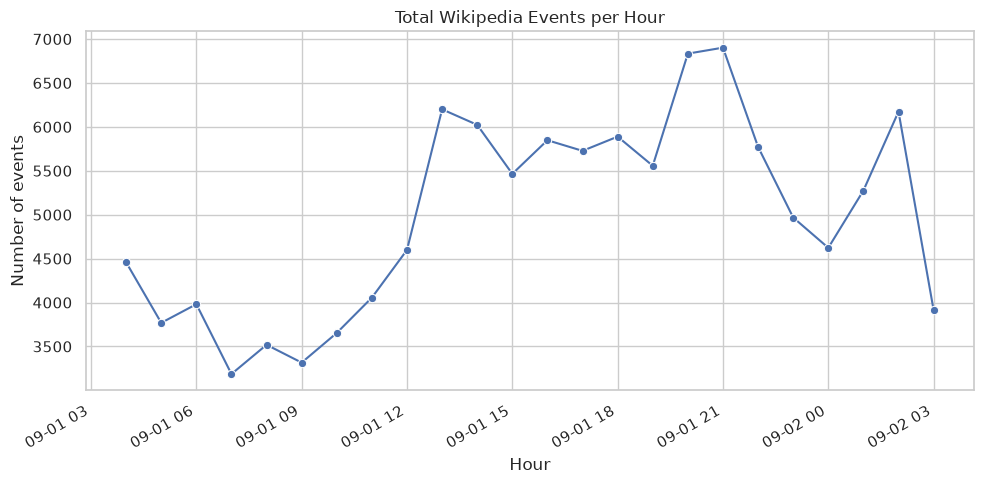

In [4]:
import os
os.makedirs("images", exist_ok=True)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=hourly, x="hour_dt", y="events", marker="o", ax=ax)
ax.set_title("Total Wikipedia Events per Hour")
ax.set_xlabel("Hour")
ax.set_ylabel("Number of events")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("images/hourly-events.png", dpi=150)
fig.savefig("images/hourly-events.svg")
plt.show()

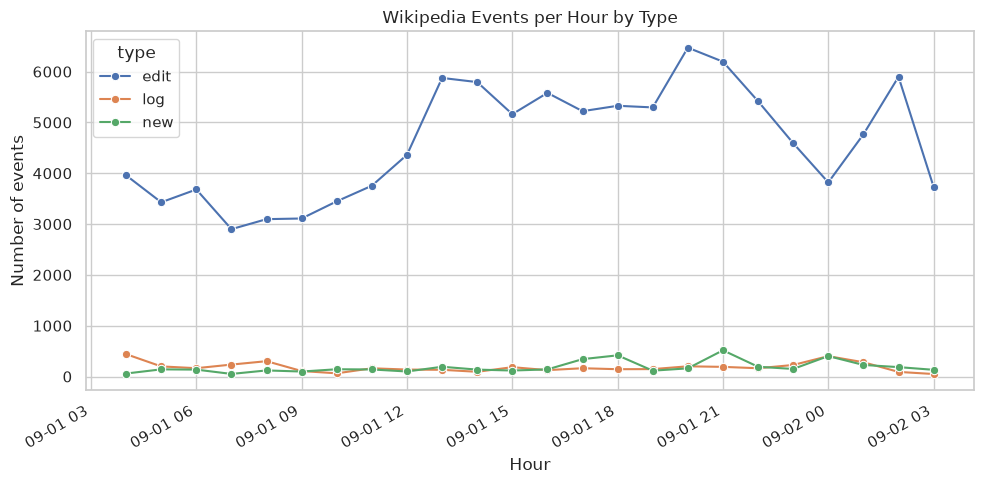

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=by_type, x="hour_dt", y="events", hue="type", marker="o", ax=ax)
ax.set_title("Wikipedia Events per Hour by Type")
ax.set_xlabel("Hour")
ax.set_ylabel("Number of events")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("images/events-by-type.png", dpi=150)
fig.savefig("images/events-by-type.svg")
plt.show()